In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from spending_analyser.analysis import monthly_spending, monthly_change
from spending_analyser.loader import load_hsbc_csv
from spending_analyser.categoriser import add_categories


df = load_hsbc_csv("../data/sample/hsbc_sample_large.csv")
df = add_categories(df)
df

spending = df[df["amount"] < 0]
by_category = spending.groupby("category")["amount"].sum()
by_category = by_category.abs().sort_values(ascending=False)
by_category


category
Rent          1200.00
Shopping        23.99
Groceries       14.62
Eating out      10.65
Transport        8.50
Name: amount, dtype: float64

In [27]:
from spending_analyser.analysis import spending_by_category


spending_by_category(df)

category
Rent          1200.00
Shopping        23.99
Groceries       14.62
Eating out      10.65
Transport        8.50
Name: amount, dtype: float64

In [28]:
totals = pd.Series(
    [300, 450, 400],
    index = pd.PeriodIndex(["2026-08", "2026-09", "2026-10"], freq="M"),
)
totals.diff()

2026-08      NaN
2026-09    150.0
2026-10    -50.0
Freq: M, dtype: float64

In [29]:
income = pd.Series([1000.0], index=pd.PeriodIndex(["2026-10"], freq="M"))
spending = pd.Series([300.0], index=pd.PeriodIndex(["2026-11"], freq="M"))

table = pd.DataFrame({"Income": income, "spending": spending})
table.fillna(0)

,Income,spending
2026-10,1000.0,0.0
2026-11,0.0,300.0


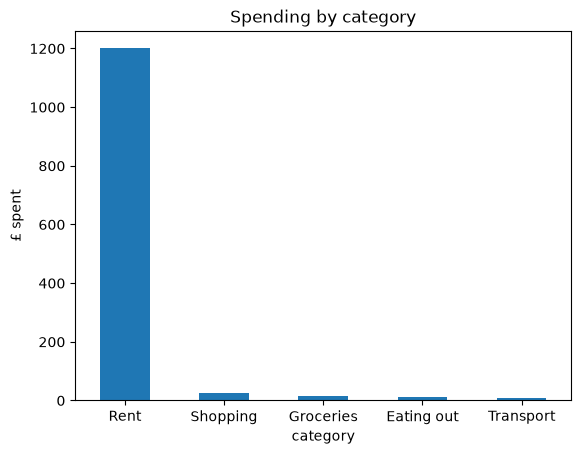

In [30]:
by_category = spending_by_category(df)
by_category.plot(kind="bar", rot=0)
plt.title("Spending by category")
plt.ylabel("£ spent")
plt.show()


c:\Users\shafr\projects\spending-analyser\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:1680: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


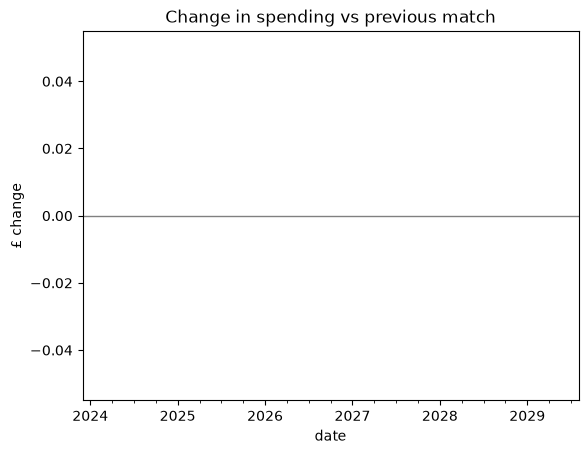

In [31]:
from spending_analyser.analysis import monthly_change

change = monthly_change(df)
change.plot(kind="line", marker="o")
plt.title("Change in spending vs previous match")
plt.ylabel("£ change")
plt.axhline(0, color="grey", linewidth=1)
plt.show()